# Part 2a. K-Means

K-Means places \(K\) centres and assigns every review to the nearest centre. It minimises

\[
J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2
\]

\(K\) is chosen by the silhouette score for \(K = 2, \ldots, 10\). The inertia curve is the elbow plot. Features are the six standardised ratings from Part 1. `Recommended` is used only to describe the clusters.

## Setup, cleaning, and scaling

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data" / "airlines_reviews.csv").exists():
    ROOT = Path(r"C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning")

DATA_PATH = ROOT / "data" / "airlines_reviews.csv"
FIG = ROOT / "figures" / "kmeans"
OUT = ROOT / "outputs" / "kmeans"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

RATING_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages",
    "Inflight Entertainment", "Value For Money", "Overall Rating",
]
SERVICE_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages", "Inflight Entertainment",
]
RANDOM_STATE = 42


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def silhouette_safe(X, labels):
    # Silhouette on non-noise points. NaN when a partition is not valid.
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) < 3 or len(np.unique(y)) < 2:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    if counts.min() < 2:
        return np.nan
    return float(silhouette_score(X[mask], y, n_jobs=-1))


print("Question folder:", FIG.parent.name + "/" + FIG.name)
print("Data file:", DATA_PATH)

Question folder: figures/kmeans
Data file: C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning\data\airlines_reviews.csv


In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
text_cols = [col for col in df.columns if pd.api.types.is_string_dtype(df[col])]
for col in text_cols:
    df[col] = df[col].str.replace("\xa0", " ", regex=False).str.strip()

verified_map = {
    "True": "True", "False": "False", "*Unverified*": "False", "NotVerified": "False",
}
n_verified_fixed = int((~df["Verified"].isin(["True", "False"])).sum())
df["Verified"] = df["Verified"].map(verified_map).fillna("False")

ife = df["Inflight Entertainment"]
n_ife_zero = int((ife == 0).sum())
ife_median = float(ife[ife > 0].median())
df.loc[ife == 0, "Inflight Entertainment"] = ife_median

n_dups = int(df["Reviews"].duplicated().sum())
df = df.drop_duplicates(subset=["Reviews"]).reset_index(drop=True)

df["Month Flown Date"] = pd.to_datetime(df["Month Flown"], format="%B %Y")
df["Year Flown"] = df["Month Flown Date"].dt.year
df["Year Bin"] = pd.cut(
    df["Year Flown"],
    bins=[2012, 2016, 2019, 2021, 2025],
    labels=["2013-2016", "2017-2019", "2020-2021", "2022-2024"],
).astype(str)
df["Review Length"] = df["Reviews"].str.len()

print(f"Rows before cleaning: {len(raw):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Verified flags corrected: {n_verified_fixed}")
print(f"Inflight Entertainment zeros imputed with median {ife_median:.0f}: {n_ife_zero}")
print(f"Duplicate reviews removed: {n_dups}")

Rows before cleaning: 8,100
Rows after cleaning:  8,098
Verified flags corrected: 3
Inflight Entertainment zeros imputed with median 4: 1
Duplicate reviews removed: 2


In [3]:
def scale_frame(frame, cols):
    scaler = StandardScaler()
    return scaler.fit_transform(frame[cols]), scaler


X_main, scaler_main = scale_frame(df, RATING_COLS)
X_no_overall, _ = scale_frame(df, [c for c in RATING_COLS if c != "Overall Rating"])
X_service, _ = scale_frame(df, SERVICE_COLS)

scale_table = pd.DataFrame({
    "feature": RATING_COLS,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
})
display(scale_table.round(3))
scale_table.round(6).to_csv(OUT / "standard_scaler_parameters.csv", index=False)

example_raw = df.loc[0, RATING_COLS].to_numpy(dtype=float)
example_z = (example_raw - scaler_main.mean_) / scaler_main.scale_
example_check = scaler_main.transform(df.loc[[0], RATING_COLS])[0]
worked = pd.DataFrame({
    "feature": RATING_COLS,
    "raw_x": example_raw,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
    "z_manual": example_z,
    "z_scaler": example_check,
})
print("Worked standardisation for review 0. z = (x - mean) / std")
display(worked.round(4))
print("Max gap between manual z and StandardScaler:", float(np.max(np.abs(example_z - example_check))))

encoder = OneHotEncoder(sparse_output=False, dtype=np.float64)
cat_cols = ["Airline", "Class", "Type of Traveller", "Year Bin"]
X_cat = encoder.fit_transform(df[cat_cols])
X_mixed = np.hstack([X_main, X_cat])
pca_mixed = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_mixed_pca = pca_mixed.fit_transform(X_mixed)

pca_viz = PCA(n_components=2, random_state=RANDOM_STATE)
XY = pca_viz.fit_transform(X_main)
loadings = pd.DataFrame(pca_viz.components_.T, index=RATING_COLS, columns=["PC1", "PC2"])
print("PCA loadings on the 6 standardised ratings:")
display(loadings.round(3))
print(
    f"PC1 + PC2 explain {pca_viz.explained_variance_ratio_.sum():.1%} of rating variance. "
    f"Mixed-feature PCA kept {X_mixed_pca.shape[1]} components "
    f"({pca_mixed.explained_variance_ratio_.sum():.1%} variance)."
)
loadings.round(4).to_csv(OUT / "pca_loadings.csv")

,feature,mean,std
0,Seat Comfort,3.415,1.397
1,Staff Service,3.570,1.527
2,Food & Beverages,3.384,1.455
3,Inflight Entertainment,3.637,1.309
4,Value For Money,3.149,1.589
5,Overall Rating,5.632,3.523


Worked standardisation for review 0. z = (x - mean) / std


,feature,raw_x,mean,std,z_manual,z_scaler
0,Seat Comfort,4.0,3.4149,1.3969,0.4188,0.4188
1,Staff Service,4.0,3.5699,1.5273,0.2816,0.2816
2,Food & Beverages,4.0,3.3842,1.4554,0.4231,0.4231
3,Inflight Entertainment,4.0,3.6371,1.3089,0.2773,0.2773
4,Value For Money,4.0,3.1486,1.5893,0.5357,0.5357
5,Overall Rating,9.0,5.6324,3.5233,0.9558,0.9558


Max gap between manual z and StandardScaler: 0.0
PCA loadings on the 6 standardised ratings:


,PC1,PC2
Seat Comfort,0.292,0.368
Staff Service,0.309,0.318
Food & Beverages,0.249,0.473
Inflight Entertainment,0.228,0.514
Value For Money,0.591,-0.379
Overall Rating,0.597,-0.363


PC1 + PC2 explain 55.3% of rating variance. Mixed-feature PCA kept 13 components (91.5% variance).


In [4]:
def name_clusters(frame, label_col, score_col="Overall Rating"):
    # Name groups from low to high mean overall rating. Noise (-1) stays Noise.
    means = frame.loc[frame[label_col] != -1].groupby(label_col)[score_col].mean().sort_values()
    labels = list(means.index)
    if len(labels) == 2:
        pretty = ["Low satisfaction", "High satisfaction"]
    elif len(labels) == 3:
        pretty = ["Low satisfaction", "Mixed satisfaction", "High satisfaction"]
    else:
        pretty = [f"Segment {i} (low to high)" for i in range(1, len(labels) + 1)]
    mapping = {lab: pretty[i] for i, lab in enumerate(labels)}
    if (frame[label_col] == -1).any():
        mapping[-1] = "Noise"
    return mapping


def profile_clusters(frame, label_col):
    rows = []
    for lab, g in frame.groupby(label_col):
        row = {
            "cluster": lab,
            "n": len(g),
            "pct": 100 * len(g) / len(frame),
            "recommend_rate": g["Recommended"].str.lower().eq("yes").mean(),
        }
        for col in RATING_COLS:
            row[col] = g[col].mean()
        rows.append(row)
    out = pd.DataFrame(rows)
    out["name"] = out["cluster"].map(name_clusters(frame, label_col))
    return out.sort_values("Overall Rating")

## Fit and choose K

,k,inertia,silhouette
0,2,34573.5774,0.2708
1,3,30797.9174,0.2163
2,4,27570.7924,0.1913
3,5,25353.3927,0.1952
4,6,23276.8173,0.1965
5,7,21614.2421,0.2007
6,8,20277.6895,0.1978
7,9,19011.2074,0.1978
8,10,18018.5410,0.2000


Selected K = 2 with silhouette 0.2708.


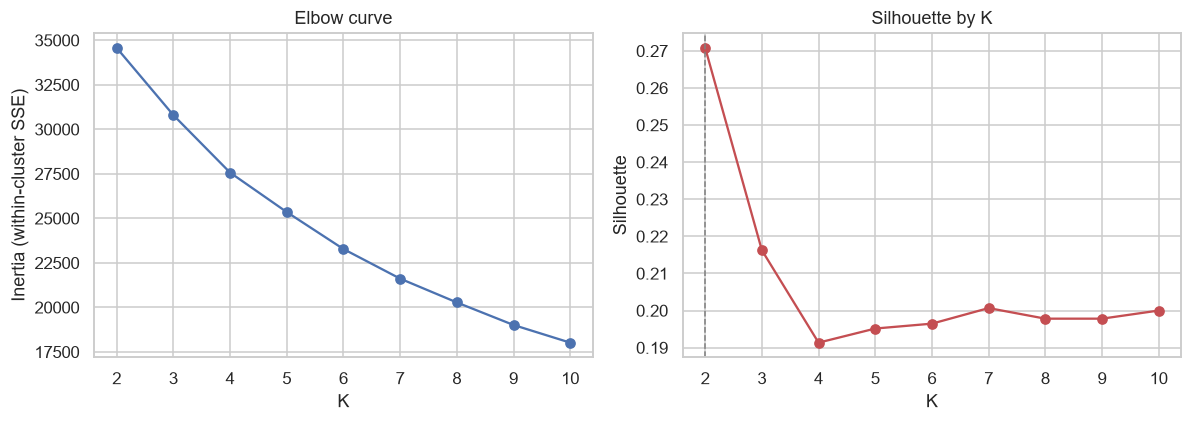

Final inertia J = 34,573.6
Centres converted back to the original rating scales:


,cluster,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating
0,0,3.03,3.12,3.07,3.41,1.64,2.21
1,1,3.73,3.94,3.65,3.83,4.40,8.47


K-Means profile:


,cluster,n,pct,recommend_rate,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,name
0,0,3670,45.32,0.064,3.032,3.121,3.071,3.407,1.638,2.205,Low satisfaction
1,1,4428,54.68,0.915,3.732,3.942,3.644,3.828,4.400,8.473,High satisfaction


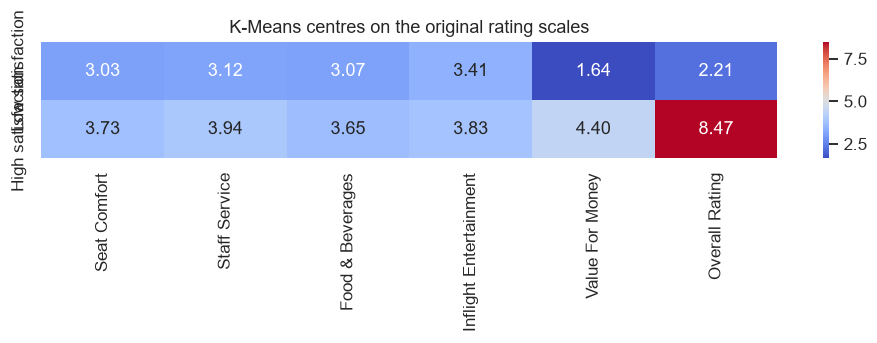

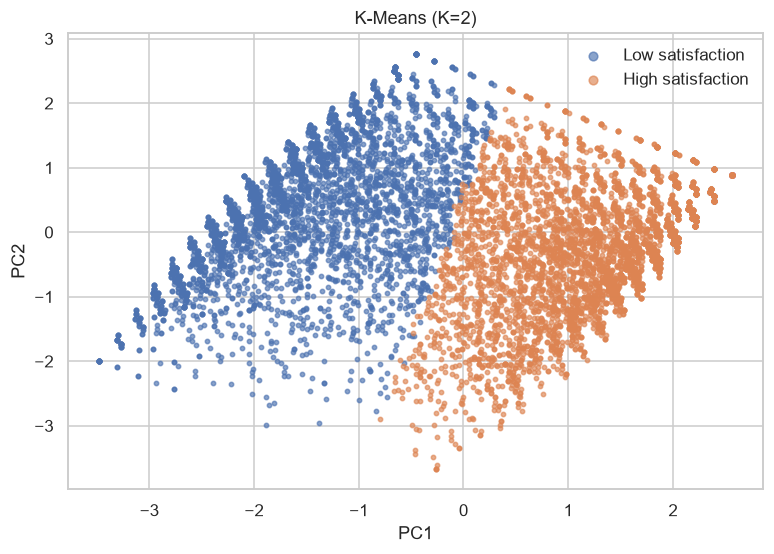

In [5]:
k_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_main)
    k_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_safe(X_main, labels),
    })
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))
k_table.to_csv(OUT / "kmeans_k_selection.csv", index=False)

best_k = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
best_k_sil = float(k_table["silhouette"].max())
print(f"Selected K = {best_k} with silhouette {best_k_sil:.4f}.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o", color="#4C72B0")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow curve")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color="#C44E52")
axes[1].axvline(best_k, color="gray", ls="--", lw=1)
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
axes[1].set_title("Silhouette by K")
save_fig(fig, "kmeans_selection.png")

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
df["kmeans"] = kmeans.fit_predict(X_main)
centers = pd.DataFrame(
    scaler_main.inverse_transform(kmeans.cluster_centers_), columns=RATING_COLS,
)
centers.insert(0, "cluster", centers.index)
print(f"Final inertia J = {kmeans.inertia_:,.1f}")
print("Centres converted back to the original rating scales:")
display(centers.round(2))
centers.round(3).to_csv(OUT / "kmeans_centers.csv", index=False)

k_profile = profile_clusters(df, "kmeans")
k_names = name_clusters(df, "kmeans")
df["kmeans_name"] = df["kmeans"].map(k_names)
print("K-Means profile:")
display(k_profile.round(3))
k_profile.round(3).to_csv(OUT / "kmeans_profile.csv", index=False)

heat = centers.set_index("cluster")[RATING_COLS]
heat.index = [k_names[i] for i in heat.index]
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("K-Means centres on the original rating scales")
save_fig(fig, "kmeans_centers.png")

fig, ax = plt.subplots(figsize=(7.2, 5.2))
for lab, g_idx in df.groupby("kmeans").groups.items():
    ax.scatter(XY[list(g_idx), 0], XY[list(g_idx), 1], s=8, alpha=0.65, label=k_names[lab])
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"K-Means (K={best_k})")
ax.legend(markerscale=2, frameon=False)
save_fig(fig, "kmeans_pca.png")

## Part 2a answer

The silhouette curve selects the \(K\) printed above. Centres are shown on the original 1–5 and 1–10 scales, so the groups can be read as passenger-satisfaction levels. Inertia \(J\) is the within-cluster sum of squares at that \(K\).